# 05 · Statistical Analysis

**Purpose:** check whether the patterns found in notebooks 03–04 are statistically robust.

**Questions answered**
1. Is sentiment associated with airline, and how strong is the association? (chi-square test, Cramér's V)
2. How certain are the airline Negative-rate estimates, especially for small airlines? (bootstrap confidence intervals)
3. Do retweet counts really differ between sentiment groups? (Kruskal–Wallis test)

These are **association** tests on observational data. They do not establish causation.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable from any folder inside the repository
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.stats import chi2_contingency, kruskal

from src.config import RANDOM_STATE
from src.data import load_clean_tweets
from src.plotting import SENTIMENT_COLORS, apply_style, save_figure

apply_style()

df = load_clean_tweets()
print(f"Rows: {len(df):,}")

Rows: 14,481


## 1. Chi-Square Test of Independence: Airline × Sentiment

- **H0:** sentiment distribution is the same for every airline (independent).
- **H1:** sentiment distribution differs by airline (associated).
- Significance level: α = 0.05

In [2]:
contingency = pd.crosstab(df["airline"], df["airline_sentiment"])
display(contingency)

chi2, p_value, degrees_of_freedom, expected = chi2_contingency(contingency)

print(f"Chi-square statistic: {chi2:,.2f}")
print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"p-value: {p_value:.3e}")
print(f"Smallest expected cell count: {expected.min():.1f} (test assumption: all >= 5)")
print(f"Decision at alpha=0.05: {'Reject H0' if p_value < 0.05 else 'Fail to reject H0'}")

airline_sentiment,Negative,Neutral,Positive
airline,,,
American,1866,432,306
JetBlue,953,722,543
Southwest,1186,664,570
US Airways,2263,381,269
United,2633,697,492
Virgin America,181,171,152


Chi-square statistic: 1,162.02
Degrees of freedom: 10
p-value: 2.241e-243
Smallest expected cell count: 81.2 (test assumption: all >= 5)
Decision at alpha=0.05: Reject H0


## 2. Effect Size: Cramér's V

With about 14,500 rows, even tiny differences produce very small p-values. Cramér's V measures **how strong** the association is, from 0 (none) to 1 (perfect).

In [3]:
n_observations = contingency.to_numpy().sum()
min_dimension = min(contingency.shape) - 1
cramers_v = np.sqrt(chi2 / (n_observations * min_dimension))

print(f"Cramer's V: {cramers_v:.4f}")

Cramer's V: 0.2003


**Interpretation:** the p-value is effectively zero, so airline and sentiment are associated. Cramér's V ≈ 0.20 is just below the conventional "medium" threshold (for a 3-category variable: about 0.07 small, 0.21 medium, 0.35 large), a **small-to-moderate** association. Airline explains part of the sentiment variation, but most of it comes from other factors.

## 3. Bootstrap 95% Confidence Intervals for Airline Negative Rates

Bootstrapping resamples each airline's tweets 2,000 times (with replacement) and recomputes the Negative rate. The middle 95% of those estimates is the confidence interval. A fixed random seed makes the result reproducible.

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_samples = 2_000
interval_rows = []

for airline, group in df.groupby("airline"):
    negative_flags = group["is_negative"].to_numpy()
    resampled_rates = np.array([
        rng.choice(negative_flags, size=len(negative_flags), replace=True).mean()
        for _ in range(bootstrap_samples)
    ])
    lower, upper = np.quantile(resampled_rates, [0.025, 0.975])
    interval_rows.append({
        "airline": airline,
        "tweets": len(group),
        "negative_rate_pct": negative_flags.mean() * 100,
        "ci_lower_pct": lower * 100,
        "ci_upper_pct": upper * 100,
    })

negative_rate_ci = pd.DataFrame(interval_rows).sort_values("negative_rate_pct")
negative_rate_ci["ci_width_pp"] = negative_rate_ci["ci_upper_pct"] - negative_rate_ci["ci_lower_pct"]
negative_rate_ci.round(2)

,airline,tweets,negative_rate_pct,ci_lower_pct,ci_upper_pct,ci_width_pp
5,Virgin America,504,35.91,31.75,40.28,8.53
1,JetBlue,2218,42.97,40.85,45.04,4.19
2,Southwest,2420,49.01,46.94,50.99,4.05
4,United,3822,68.89,67.37,70.36,2.98
0,American,2604,71.66,69.97,73.43,3.46
3,US Airways,2913,77.69,76.14,79.20,3.06


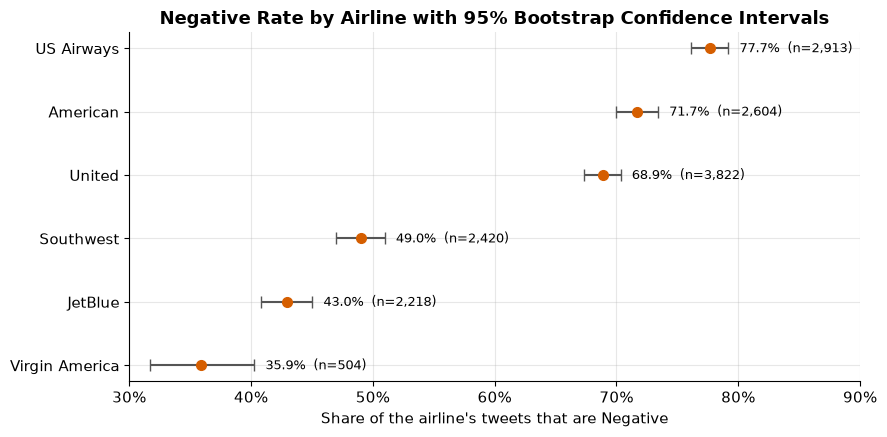

In [5]:
y_positions = np.arange(len(negative_rate_ci))
error_bars = np.vstack([
    negative_rate_ci["negative_rate_pct"] - negative_rate_ci["ci_lower_pct"],
    negative_rate_ci["ci_upper_pct"] - negative_rate_ci["negative_rate_pct"],
])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(negative_rate_ci["negative_rate_pct"], y_positions, xerr=error_bars,
            fmt="o", markersize=7, color=SENTIMENT_COLORS["Negative"], ecolor="#555555", capsize=4)
for y, (_, row) in zip(y_positions, negative_rate_ci.iterrows()):
    ax.annotate(f"{row['negative_rate_pct']:.1f}%  (n={row['tweets']:,})", (row["ci_upper_pct"], y),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_yticks(y_positions)
ax.set_yticklabels(negative_rate_ci["airline"])
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(30, 90)
ax.set_xlabel("Share of the airline's tweets that are Negative")
ax.set_title("Negative Rate by Airline with 95% Bootstrap Confidence Intervals")
plt.tight_layout()
save_figure("negative_rate_confidence_intervals.png")
plt.show()

In [6]:
# Which neighbouring airlines (in rank order) have overlapping intervals?
ordered = negative_rate_ci.reset_index(drop=True)
for i in range(len(ordered) - 1):
    lower_airline, higher_airline = ordered.loc[i], ordered.loc[i + 1]
    overlap = lower_airline["ci_upper_pct"] >= higher_airline["ci_lower_pct"]
    print(f"{lower_airline['airline']:<15} vs {higher_airline['airline']:<15}: "
          f"{'intervals overlap - ranking uncertain' if overlap else 'no overlap - clearly different'}")

Virgin America  vs JetBlue        : no overlap - clearly different
JetBlue         vs Southwest      : no overlap - clearly different
Southwest       vs United         : no overlap - clearly different
United          vs American       : intervals overlap - ranking uncertain
American        vs US Airways     : no overlap - clearly different


**Interpretation:** Virgin America's interval is the widest (about ±4 points) because it has only 504 tweets. The split between the lower-negative group (Virgin America, JetBlue, Southwest) and the higher-negative group (United, American, US Airways) is clear, with no overlap between the groups. Within the groups, only United and American have overlapping intervals, so their order (68.9% vs 71.7%) is uncertain. Every other adjacent pair is clearly separated.

## 4. Do Retweet Counts Differ by Sentiment?

Retweet counts are heavily skewed (most are 0), so a **Kruskal–Wallis** rank test is used instead of ANOVA, which assumes normality.

In [7]:
sentiment_order = ["Positive", "Neutral", "Negative"]
display(df.groupby("airline_sentiment")["retweet_count"].agg(["count", "mean", "median", "max"]).reindex(sentiment_order).round(4))

retweet_groups = [df.loc[df["airline_sentiment"] == s, "retweet_count"].to_numpy() for s in sentiment_order]
h_statistic, kruskal_p_value = kruskal(*retweet_groups)

# Epsilon-squared effect size for Kruskal-Wallis
epsilon_squared = h_statistic * (len(df) + 1) / (len(df) ** 2 - 1)

print(f"Kruskal-Wallis H: {h_statistic:.2f}")
print(f"p-value: {kruskal_p_value:.3e}")
print(f"Epsilon-squared effect size: {epsilon_squared:.4f}")

,count,mean,median,max
airline_sentiment,,,,
Positive,2332,0.0690,0.0,22
Neutral,3067,0.0613,0.0,28
Negative,9082,0.0941,0.0,44


Kruskal-Wallis H: 78.45
p-value: 9.229e-18
Epsilon-squared effect size: 0.0054


**Interpretation:** the difference is statistically significant: Negative tweets are more often retweeted. The effect size is very small (ε² well below 0.01), so sentiment explains almost none of the variation in retweets. This is a clear case of **statistical significance without practical importance**.

## 5. Statistical Findings

In [8]:
print(f"1. Airline and sentiment are associated (chi-square p = {p_value:.1e}) with a small-to-moderate effect (Cramer's V = {cramers_v:.3f}).")
widest = negative_rate_ci.loc[negative_rate_ci["ci_width_pp"].idxmax()]
print(f"2. The widest Negative-rate interval is {widest['airline']} ({widest['ci_lower_pct']:.1f}% to {widest['ci_upper_pct']:.1f}%), "
      f"due to its small sample of {widest['tweets']:,} tweets.")
print(f"3. Retweets differ by sentiment (p = {kruskal_p_value:.1e}), but the effect is tiny (epsilon-squared = {epsilon_squared:.4f}).")

1. Airline and sentiment are associated (chi-square p = 2.2e-243) with a small-to-moderate effect (Cramer's V = 0.200).
2. The widest Negative-rate interval is Virgin America (31.7% to 40.3%), due to its small sample of 504 tweets.
3. Retweets differ by sentiment (p = 9.2e-18), but the effect is tiny (epsilon-squared = 0.0054).


- The two-group airline split seen in the EDA holds up statistically.
- Point rankings inside each group are less certain, especially for Virgin America.
- Retweet differences are real but practically small, so retweets should not drive major decisions.
- None of these tests imply causation.